In [ ]:
import torch
import time
import matplotlib.pyplot as plt
import optuna
import time
import numpy as np
from tabulate import tabulate # pip install tabulate (for pretty printing)

📘 How to Use This Notebook
This is a standalone, self-teaching lecture notebook.

How to Study:

Read all markdown cells carefully - they contain explanations, mental models, and reasoning
Run code cells sequentially - don't skip ahead as each builds on the previous
Pause at "Stop & Think" prompts - make predictions before running the next cell
Experiment with the code - change parameters and see what happens
Time Commitment: ~(    ) hours for complete understanding

Learning Outcomes: After completing this notebook, you will be able to:

- Explain what is Optuna.
- Why it was create and what problems it solve.
- How to use Optuna

# Part 0: Hyperparameter Tuning - The problem

### 0.0: What is model hyperparameter and how they differ from model parameters:

  In any model there are two types of variables, parameter which are internal configuration variables that the model learn directly from the training data during training, while hyperparameters are external configuration variables whose values are set manually before the training process begins and it dedicate how the model learns. The following table shows the key differences between them:

```
| Feature                          | Parameters                      | Hyperparameter                                           |
|----------------------------------|---------------------------------|----------------------------------------------------------|
| Origin                           | learned automatically from data | Set manually by user or engine                           |
| Determination Time               | During training                 | Before Training                                          |
| Can they change during training? | Yes, Updates continuously       | Usually remain fixed                                     |
| Examples                         | Weights , Biases                | Learning rate, batch size, number of epochs, layer depth |
```

### 0.1: What is hyperparameters tuning?

  Is the process of finding the best set of configuration settings for a machine learning model before training it to maximize its performance or to make it perform well on unseen data.

Why we need hyperparameters tuning?

  Because different hyperparameters values dramatically affect model's performance (accuracy, stability, and generalization), so we need to find the set values that make the model perform as we want before training it.
  
  Here is an example that shows how different learning values can affect the model performance:
  If the learning rate is too high: The model might overshoot the optimal solution and never converge.
  If the learning rate is too low: The model will take forever to train and might get stuck in a sub-optimal trap (Local Minimum).

In [ ]:
# 1. Create a simple dataset: y = 3x + 2
torch.manual_seed(42)

X = torch.linspace(-2, 2, 300).reshape(-1, 1)
y = 3 * X + 2 + 0.2 * torch.randn_like(X)

# 2. Define three learning rates
learning_rates = {
    "Too High (1.0)": 1.0,
    "Reasonable (0.05)": 0.05,
    "Too Low (0.0001)": 0.0001
}

results = {}

# 3. Train the same model using each learning rate
for name, lr in learning_rates.items():

    torch.manual_seed(0)

    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_function = torch.nn.MSELoss()

    losses = []
    start_time = time.perf_counter()

    for epoch in range(500):

        optimizer.zero_grad()

        predictions = model(X)
        loss = loss_function(predictions, y)

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        # Stop if training diverges
        if not torch.isfinite(loss):
            break

        # Stop when the model reaches the target loss
        if loss.item() < 0.05:
            break

    elapsed_time = time.perf_counter() - start_time

    results[name] = {
        "losses": losses,
        "epochs": len(losses),
        "time": elapsed_time,
        "final_loss": losses[-1]
    }

    print(f"\n{name}")
    print(f"Epochs: {len(losses)}")
    print(f"Training time: {elapsed_time:.4f} seconds")
    print(f"Final loss: {losses[-1]:.6f}")

# 4. Visualize the learning curves
plt.figure(figsize=(10, 5))

for name, result in results.items():
    plt.plot(result["losses"], label=name)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Effect of Learning Rate on Model Training")
plt.legend()
plt.grid(True)
plt.show()


### 0.2: Early techniques used to perform hyperparameters:

**0.2.1: Manual Search (Oldest Technique):**

This is the earliest and simplest approach. The machine learning engineer chooses hyperparameters based on experience, trains the model, observes the results, and adjusts them iteratively. This process relies entirely on human intuition.

Advantages:
- Simple.
- No additional tools required.
- Helps beginners understand the effect of each hyperparameter.
  
Disadvantages:
- Time-consuming.
- Depends heavily on experience.
- Can easily miss the best hyperparameter values.

**0.2.2: Grid Search (Traditional Standard):**

Grid search systematically test all the combinations for all the possible values for all the hyperparameters. So we define a fixed grid of values for each hyperparameter, and the algorithm tests every single possible combination (the Cartesian product).

For example is we want to tune the following:

Learning Rate = [0.1, 0.01, 0.001]

Batch Size = [16, 32, 64]

Optimizer = [SGD, Adam]

The Grid Search tests every combination:

```
|Trial  |Learning Rate  | Batch Size   | Optimizer |
|-------|---------------|--------------|-----------|
| 1	| 0.1	        | 16	       | SGD       |
| 2	| 0.1	        | 16 	       | Adam      |
| 3	| 0.1	        | 32	       | SGD       |
| ...	| ...	        | ...	       | ...       |
| 18	| 0.001 	| 64	       | Adam      |

```
Advantages:

- Very easy to implement.
- Guaranteed to test every specified combination.
- Good when there are only a few hyperparameters.

Disadvantages:

- It suffers heavily from combinatorial explosion. Adding parameters or finer value increments causes the number of required training runs to skyrocket into thousands or millions.
  
  For example if we have 6 hyperparameters, and each has 10 values, then the grid search must perform 10⁶ = 1,000,000.

**0.2.3: Random Search (Blind Sampling):**

Instead of checking every point on a rigid grid, the engineer define statistical distributions (or a pool of choices) for each parameter, and the algorithm randomly selects a fixed number of combinations to test. The main problem in this search is that there is no memory from previous trails about what went right or wrong so the algorithm may repeat it again, this is called blind search.

Advantages:

- Much faster than Grid Search.
- Explores more of the search space.
- Works well in high-dimensional problems.

Disadvantages:

- Still random.
- May miss the optimum.
- Does not learn from previous trials.

# Part 1: The need for Optuna:

As traditional hyperparameter tuning approaches have limitations like:
- Grid Search can require an enormous number of experiments.
- Random Search does not learn from previous trials.
- Manual tuning depends heavily on human experience.
- Deep learning experiments can consume substantial computational resources.

optuna was developed to handle these limitations as we will see.

### 1.1: What is Optuna?
Optuna is a framework for finding the optimal hyperparameter values by trial and error for higher-excellent performance. It employs a Bayesian Optimization algorithm called Tree-structured Parzen Estimator.

We can also define Optuna as tool used to orchestrate the experiment process to find the optimum set of hyperparameters values. It
```
- Suggests hyperparameters
- Runs your objective function
- Receives the result
- Records the result
- Decides what to try next
- Repeats
- Keeps the best configuration
```

### 1.2: How it differ from old techniqus?
Optuna sits between brute‑force and full Bayesian frameworks. It provides intelligent samplers (e.g., TPE, CMA‑ES) that learn from past trials (intelligent hyperparameter sampling), supports pruning (stop bad trials early), and allows expressive, conditional search spaces defined inside the objective function.

### 1.3: How TPE (Default Optuna algorithm) works?

Let us see how Optuna tackled the problems faced by previous techniques:

Optuna use a method called Tree-Structured Parzen Estimator which is probabilistic sampling algorithm. Let us understand the names first then get deeper in how it works:

| Word | Meaning | Explanation |
|---|---|---|
| Tree-structured | Supports conditional and hierarchical search spaces. | Some hyperparameters depend on other hyperparameters. |
| Parzen | Uses probability density estimation. | Estimates where good and bad hyperparameter values are likely to occur. |
| Estimator | Estimates probability distributions from observed data. | Uses previous trial results to guide future hyperparameter suggestions. |

So here instead of trying every combination or randomly select them, we run n number of trails, then model "good" vs "bad" trails distribution, so it can answer two questions:
 1. What parameter values are associated with good performance?
 2. What parameter values are associated with poor performance?

So instead of predicting the performance, it focus on the good trails distribution and ask wehtehr the hyperparameter value belongs to the distribution. In other words, it look if the hyperparameter look similar to the hyperparameters that have already produced good results.

This is how it mathimatically models the two probability distributions:

probability distribution of promising parameter values: l(x)=p(x\mid y < y^*)

probability distribution of less promising parameter values: g(x)=p(x\mid y >= y^*)

Where:
- x = hyperparameter values.
- y = objective value (such as validation loss).
- y^* = a threshold separating good and bad trials.

So far this is for the candidates we already have for the the first n trials, then for the next candidate hyperparameter value TPE samples its values from the good distribution l(x) by using this ratio:

   l(x) / g(x)

A higher ratio indicates that a candidate is much more likely under the good distribution than under the bad distribution.

Note: You might be thinking well if all techniques will need the same number of trails or initial trails then why to use Optuna?! The advantage of Optuna's TPE is not necessarily performing fewer trials. It is making better use of the information collected from previous trials.

**So in clear steps we can say that Optuna (TPE) works as follows:**

  1. Initial Random Trials (Warm-up):
     
     Before building any statistical model, Optuna runs a few initial trials (controlled by n_startup_trials, usually set to 10) using purely random sampling. This builds an initial baseline dataset of parameters and their corresponding performance scores.
     
  2. Splitting the results (good VS bad):
 
     Once enough trials are complete, Optuna splits the history into two distinct groups based on a threshold (often determined by a percentile parameter called $\gamma$, e.g., the top 20% vs. the remaining 80%).
     - Group 1: Configurations that yielded good (low error / high accuracy) results.
     - Group 2: Configurations that yielded bad results.
     
  3. Building the Distributions (l(x) and g(x))
  4. 
     Following the Bayesian approach, Optuna fits probability density functions (often using Gaussian Mixture Models) to both groups:
     l(x) = P(x \ y < y*): The probability distribution of parameters (x) given that the score (y) is better than the threshold (y*) (the "good" distribution).
     g(x) = P(x \ y >= y*): The probability distribution of parameters (x) for the remaining trials (the "bad" distribution).
     
  6. Choose the next trail values: The model set values and compute the ratio for them using l(x) / g(X) to see from which distribution it will come.

### 1.4: Core Cocepts:



### 1.5: Code Example 1: The "Hello World" of Optuna

1. Study:
- Study represents a single optimization task or experiment, serving as the central container for managing the entire hyperparameter tuning process.
- Think of it as a project or experiment that manages multiple training attempts.
- Inside it we define the goal of the optimization task (like we want to minimize or maximize a function so it choose the values based on it.)

2. Trial: 
- A Trial represents one experiment within a Study.
- Each trial contains:
    - Suggested hyperparameter values.
    - The objective value returned by the function.
    - Its state (complete, pruned, failed, etc.).
    - Additional metadata.

- For example suppose we want to train a Random Forest five times with different hyperparameters:

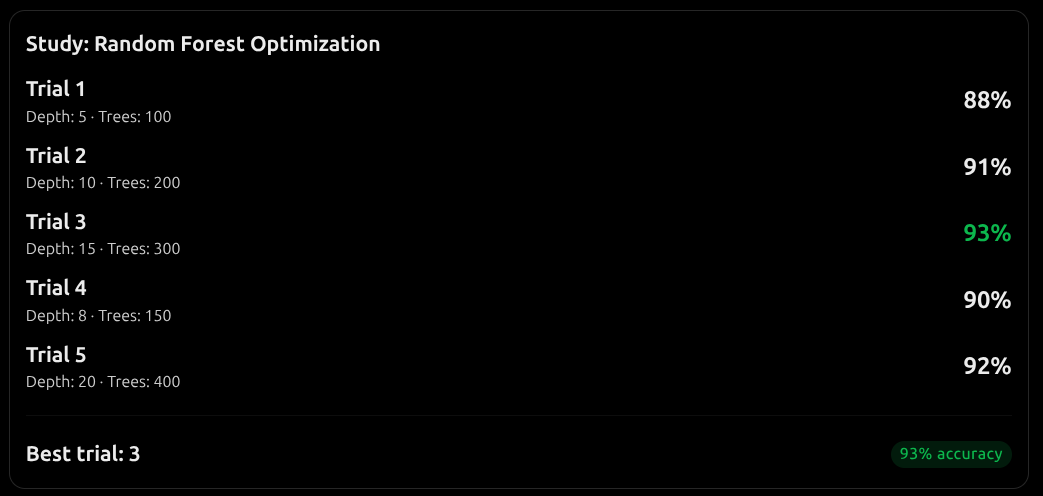

3. Objective Function
- The objective function defines what Optuna should optimize.
- It tells Optuna:
    1. Which hyperparameters to suggest.
    2. How to train the model.
    3. How to evaluate the model.
    4. Which metric to return.
For example:

```
def objective(trial):

    max_depth = trial.suggest_int(
        "max_depth", 2, 30
    )

    n_estimators = trial.suggest_int(
        "n_estimators", 50, 500
    )

    model = RandomForestClassifier(
        max_depth=max_depth,
        n_estimators=n_estimators
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_valid)

    accuracy = accuracy_score(
        y_valid, predictions
    )

    return accuracy

```

4. Sampler
- The sampler decides which hyperparameter values Optuna should try next. The defult is TPE but there are other samplers you can choose

5. Pruner
- The pruner decides whether a trial should stop early because its intermediate performance is unpromising.

6. Search Space:
- A search space defines which hyperparameters Optuna can change and the possible values it can choose.

- Optuna provides three main suggestion methods.

        | Method | Purpose | Example |
        |---|---|---|
        | suggest_int() | Integer values | Number of trees |
        | suggest_float() | Decimal values | Learning rate |
        | suggest_categorical() | Choices from a list | Optimizer type |



In [ ]:
# 1. Define the Objective Function
def objective(trial):
    # Suggest hyperparameters dynamically
    x = trial.suggest_float('x', -10, 10)
    y = trial.suggest_float('y', -10, 10)
    
    # The function we want to minimize: (x - 2)^2 + (y + 3)^2
    # Minimum is at x=2, y=-3
    return (x - 2)**2 + (y + 3)**2

# 2. Create a Study object (direction='minimize' or 'maximize')
study = optuna.create_study(direction='minimize', study_name='math_function')

# 3. Run the optimization
study.optimize(objective, n_trials=100)

# 4. Inspect the results
print(f"Best trial value: {study.best_trial.value:.4f}")
print(f"Best parameters: {study.best_trial.params}")

### 1.6: Code Example 2:

### 1.7: Comparing the imporvement Optuna intoduce in hyperparameter tuning to other techniques

In [ ]:
# Suppress Optuna's verbose logging for a cleaner classroom output
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==========================================
# 1. THE SIMULATED EXPENSIVE FUNCTION
# ==========================================
def expensive_objective(x, y):
    """
    Simulates a machine learning model that takes 50ms to train.
    We want to minimize: (x - 2)^2 + (y + 3)^2
    True minimum is at x=2, y=-3 (Value = 0.0)
    """
    time.sleep(0.05)  # Simulate 50ms of heavy computation per evaluation
    return (x - 2)**2 + (y + 3)**2

# We consider the model "good enough" if the loss is less than 0.5
TARGET_THRESHOLD = 0.5 
MAX_EVALUATIONS = 100  # The maximum budget we allow for Grid/Random

print(f"🎯 Target Threshold (Good Enough): < {TARGET_THRESHOLD}")
print(f"💰 Max Budget: {MAX_EVALUATIONS} evaluations")
print("-" * 50)

# ==========================================
# 2. GRID SEARCH (The Brute Force Way)
# ==========================================
print("\n🔲 Running GRID SEARCH...")
start_time = time.time()

# Create a 10x10 grid (100 total combinations)
x_grid = np.linspace(-10, 10, 10)
y_grid = np.linspace(-10, 10, 10)

grid_best_val = float('inf')
grid_evals = 0

# Grid search MUST evaluate every single point. It cannot stop early.
for x in x_grid:
    for y in y_grid:
        val = expensive_objective(x, y)
        grid_evals += 1
        if val < grid_best_val:
            grid_best_val = val

grid_time = time.time() - start_time
print(f"✅ Grid Search finished. Best value: {grid_best_val:.4f}")

# ==========================================
# 3. RANDOM SEARCH (The Blind Way)
# ==========================================
print("\n🎲 Running RANDOM SEARCH...")
start_time = time.time()

random_best_val = float('inf')
random_evals = 0

# Random search blindly samples the space. It also cannot stop early natively.
for _ in range(MAX_EVALUATIONS):
    x = np.random.uniform(-10, 10)
    y = np.random.uniform(-10, 10)
    
    val = expensive_objective(x, y)
    random_evals += 1
    if val < random_best_val:
        random_best_val = val

random_time = time.time() - start_time
print(f"✅ Random Search finished. Best value: {random_best_val:.4f}")

# ==========================================
# 4. OPTUNA (The Smart Way)
# ==========================================
print("\n🧠 Running OPTUNA (Bayesian Optimization)...")

def optuna_objective(trial):
    x = trial.suggest_float('x', -10, 10)
    y = trial.suggest_float('y', -10, 10)
    return expensive_objective(x, y)

# Callback to stop Optuna EARLY once it finds a "good enough" solution
def stop_when_good_enough(study, trial):
    if study.best_value < TARGET_THRESHOLD:
        study.stop()

start_time = time.time()
study = optuna.create_study(direction='minimize')

# Optuna will run up to 100 trials, BUT will stop early if it hits the threshold!
study.optimize(optuna_objective, n_trials=MAX_EVALUATIONS, callbacks=[stop_when_good_enough])

optuna_time = time.time() - start_time
optuna_evals = len(study.trials)
optuna_best_val = study.best_value

print(f"✅ Optuna finished. Best value: {optuna_best_val:.4f}")

# ==========================================
# 5. THE SHOWDOWN: COMPARISON
# ==========================================
print("\n" + "="*60)
print("🏆 THE SHOWDOWN: RESULTS COMPARISON")
print("="*60)

results = [
    ["Grid Search", grid_evals, f"{grid_time:.2f}s", f"{grid_best_val:.4f}"],
    ["Random Search", random_evals, f"{random_time:.2f}s", f"{random_best_val:.4f}"],
    ["Optuna (TPE)", optuna_evals, f"{optuna_time:.2f}s", f"{optuna_best_val:.4f}"]
]

print(tabulate(results, headers=["Method", "Evaluations", "Time Taken", "Best Score"], tablefmt="grid"))

print("\n💡 KEY TAKEAWAY FOR STUDENTS:")
print(f"Optuna achieved a similar/better score using only {optuna_evals} evaluations,")
print(f"while Grid/Random blindly used {MAX_EVALUATIONS}. Optuna was {MAX_EVALUATIONS/optuna_evals:.1f}x more efficient!")

### 1.8: Summary of the Framework flow

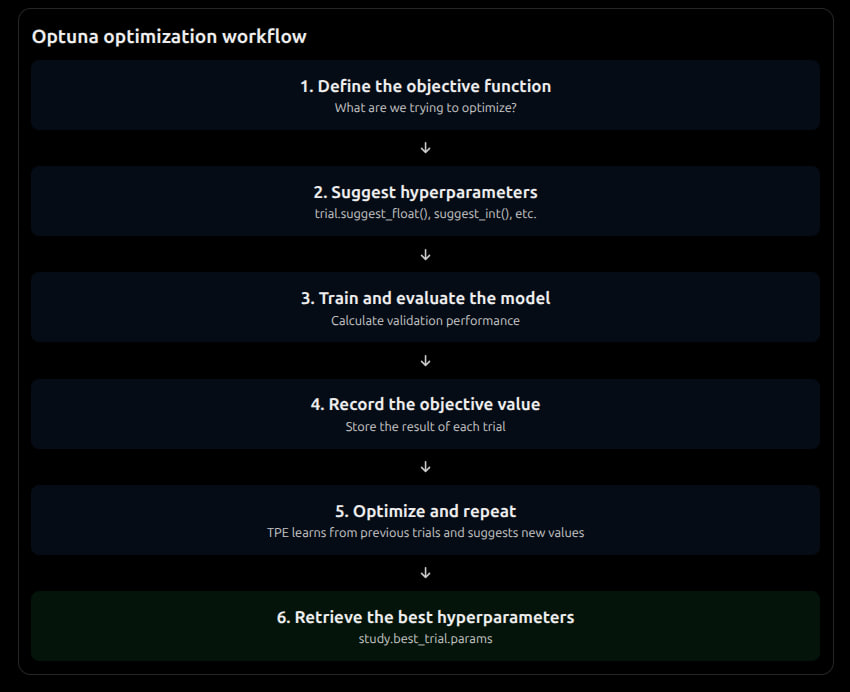

# Part 2: Core Concepts

### 2.1: Samplers (Search Algorithms)

TPESampler (default): Tree-structured Parzen Estimator, a Bayesian-style method that works well for most problems
GPSampler: Gaussian-process-based Bayesian optimization
CmaEsSampler: CMA-ES, good for continuous, lower-dimensional spaces
NSGAIISampler / NSGAIIISampler: evolutionary algorithms for multi-objective problems
RandomSampler and GridSampler: baselines
QMCSampler: quasi-Monte Carlo
BoTorchSampler: Bayesian optimization via BoTorch
AutoSampler (via OptunaHub): automatically picks a suitable sampler

### 2.2: Pruers (Early Stoping of bad trails)

# Part3: Ecosystem

### 3.1: Optuna Dashboard 
 A real-time web UI for monitoring studies (pip install optuna-dashboard, then optuna-dashboard sqlite:///optuna.db). There’s also a VS Code extension.

### 3.2: optuna-integration
 separate package with callbacks and pruning hooks for PyTorch Lightning, Keras, XGBoost, LightGBM, scikit-learn, fastai, and others

### 3.3: OptunaHub
 a community registry of samplers, pruners, and benchmarks

### 3.4: Optuna CLI
manage studies from the command line